# Exploratory data analysis: Avangrid AMI meter data

This notebook takes a first look at the hourly smart-meter (AMI) data and the hourly weather data supplied for the Avangrid hackathon. The goals are to:

1. Load all of the meter-data CSVs efficiently.
2. Check data quality: missing values, unique values per column, and the spread of the categorical columns.
3. Export a few per-customer summaries for follow-up checks.
4. Save the full dataset to a DuckDB database so later notebooks can query it with SQL instead of re-reading the CSVs.
5. Load the weather data, clean it and look at how temperature changes over the day in each month.

The notebook should be run from the project folder, the one that contains `onedrive-export/`. All paths below are relative to it.

## Setup

We use **polars** rather than pandas to read and summarise the meter data. The dataset is a few hundred million rows spread across many CSV files. Polars reads files in parallel on all CPU cores and can work *lazily*: it builds a query plan and only reads the data it needs when the result is requested. That makes it several times faster than looping over the files with `pd.read_csv` and concatenating them, and it uses far less memory.

**DuckDB** is used to store the result as a SQL table, and **matplotlib** to draw the weather chart.

In [1]:
import os
import time

import duckdb
import matplotlib.pyplot as plt
import polars as pl

## Define the meter-data source and column types

All meter-data files have the same eight columns, so a single glob pattern (`**/*.csv`) picks up every CSV in every subfolder of `meter-data/`.

We set each column's type explicitly instead of letting polars guess:

- **Small integer types** (`Int8`, `Int32`): `hour_ending` only runs from 1 to 24, and customer numbers fit easily in 32 bits. The default 64-bit integers would use 2–8 times as much memory for no benefit.
- **`Date`** for `usage_date`, so it can be filtered, sorted and grouped as a date rather than as text.
- **`Categorical`** for `day_type` and `interval_type`: each has only a handful of distinct values, so storing each value once and keeping a small code per row is far cheaper than storing the text on every row.

Together these types keep the full dataset small enough to fit in memory: roughly a third of the size it would be with default types.

In [2]:
DATA_GLOB = 'onedrive-export/Data/meter-data/**/*.csv'

SCHEMA = {
    'CUSTOMER_NUMBER': pl.Int32,
    'usage_date': pl.Date,
    'hour_ending': pl.Int8,
    'day_type': pl.Categorical,
    'hourly_kwh': pl.Float64,
    'interval_count': pl.Int8,
    'interval_type': pl.Categorical,
    'is_complete_hour': pl.Int8,
}

## Scan the files lazily

`pl.scan_csv` does not read any data yet. It creates a `LazyFrame`: a description of where the data lives and what it looks like. Each later query is optimised and run against the files only when `.collect()` is called, so we can compute summaries over the whole dataset without first loading all of it into memory.

`encoding='utf8-lossy'` replaces any malformed characters instead of failing. The original pandas code used `latin1` to be safe, but polars doesn't support it. The files checked so far are plain ASCII, so this changes nothing in practice.

In [3]:
t0 = time.time()

lf = pl.scan_csv(
    DATA_GLOB,
    schema_overrides=SCHEMA,
    encoding='utf8-lossy',
)

schema = lf.collect_schema()
columns = schema.names()
schema

Schema([('CUSTOMER_NUMBER', Int32),
        ('usage_date', Date),
        ('hour_ending', Int8),
        ('day_type', Categorical),
        ('hourly_kwh', Float64),
        ('interval_count', Int8),
        ('interval_type', Categorical),
        ('is_complete_hour', Int8)])

## Null and unique values per column

This is the first data-quality check:

- **Null counts** show whether any column has gaps that would need filling or filtering before modelling.
- **Unique counts** show each column's cardinality. They help confirm that a column holds what we expect (for example, 24 hours, or 2 day types), flag columns with only one value (which carry no information), and show how many customers and dates the data covers.

All of these figures are computed in a **single pass** over the data: one `select` holds every expression, so polars reads the files once instead of once per column. `engine='streaming'` processes the files in chunks, which keeps memory use low.

In [4]:
summary = lf.select(
    pl.len().alias('__rows'),
    *[pl.col(c).null_count().alias(f'{c}__nulls') for c in columns],
    *[pl.col(c).n_unique().alias(f'{c}__unique') for c in columns],
).collect(engine='streaming')

n_rows = summary['__rows'][0]
summary_df = pl.DataFrame({
    'column': columns,
    'dtype': [str(schema[c]) for c in columns],
    'null_count': [summary[f'{c}__nulls'][0] for c in columns],
    'unique_count': [summary[f'{c}__unique'][0] for c in columns],
})

print(f'Scanned {n_rows:,} rows in {time.time()-t0:.2f} seconds.')
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, thousands_separator=True):
    print(summary_df)

Scanned 298,032,553 rows in 10.51 seconds.
┌──────────────────┬─────────────┬────────────┬──────────────┐
│ column           ┆ dtype       ┆ null_count ┆ unique_count │
│ ---              ┆ ---         ┆ ---        ┆ ---          │
│ str              ┆ str         ┆ i64        ┆ i64          │
╞══════════════════╪═════════════╪════════════╪══════════════╡
│ CUSTOMER_NUMBER  ┆ Int32       ┆ 0          ┆ 34,238       │
│ usage_date       ┆ Date        ┆ 0          ┆ 365          │
│ hour_ending      ┆ Int8        ┆ 0          ┆ 24           │
│ day_type         ┆ Categorical ┆ 0          ┆ 2            │
│ hourly_kwh       ┆ Float64     ┆ 0          ┆ 191,555      │
│ interval_count   ┆ Int8        ┆ 0          ┆ 2            │
│ interval_type    ┆ Categorical ┆ 0          ┆ 2            │
│ is_complete_hour ┆ Int8        ┆ 0          ┆ 1            │
└──────────────────┴─────────────┴────────────┴──────────────┘


## Value counts for non-numeric columns

For the non-numeric columns (`usage_date`, `day_type` and `interval_type`) we count how often each value appears.

- For **`day_type`** and **`interval_type`**, this shows how the data is split between categories, and whether any category is so rare it may need special handling.
- For **`usage_date`**, a roughly constant count per day means the same customers report every day. Days with noticeably fewer rows point to missing data or to the daylight-saving clock changes, which shorten or lengthen a day by an hour.

`usage_date` is treated as non-numeric here because it is a date, so a count per value is useful. This prints one row per date, about 365 rows.

In [5]:
non_numeric_cols = [c for c in columns if not schema[c].is_numeric()]

for c in non_numeric_cols:
    counts = (
        lf.group_by(c)
        .agg(pl.len().alias('count'))
        .sort(c)
        .collect(engine='streaming')
    )
    with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, thousands_separator=True):
        print(f'\nValue counts for {c} ({counts.height:,} distinct values):')
        print(counts)

print(f'\nEDA summary finished in {time.time()-t0:.2f} seconds.')


Value counts for usage_date (365 distinct values):
┌────────────┬─────────┐
│ usage_date ┆ count   │
│ ---        ┆ ---     │
│ date       ┆ u32     │
╞════════════╪═════════╡
│ 2025-09-01 ┆ 812,759 │
│ 2025-09-02 ┆ 812,751 │
│ 2025-09-03 ┆ 812,813 │
│ 2025-09-04 ┆ 812,826 │
│ 2025-09-05 ┆ 812,667 │
│ 2025-09-06 ┆ 812,873 │
│ 2025-09-07 ┆ 812,952 │
│ 2025-09-08 ┆ 812,982 │
│ 2025-09-09 ┆ 812,296 │
│ 2025-09-10 ┆ 812,439 │
│ 2025-09-11 ┆ 813,120 │
│ 2025-09-12 ┆ 813,144 │
│ 2025-09-13 ┆ 813,155 │
│ 2025-09-14 ┆ 813,160 │
│ 2025-09-15 ┆ 813,389 │
│ 2025-09-16 ┆ 813,477 │
│ 2025-09-17 ┆ 813,489 │
│ 2025-09-18 ┆ 813,539 │
│ 2025-09-19 ┆ 813,568 │
│ 2025-09-20 ┆ 813,624 │
│ 2025-09-21 ┆ 813,696 │
│ 2025-09-22 ┆ 813,729 │
│ 2025-09-23 ┆ 813,773 │
│ 2025-09-24 ┆ 813,803 │
│ 2025-09-25 ┆ 813,777 │
│ 2025-09-26 ┆ 813,752 │
│ 2025-09-27 ┆ 813,752 │
│ 2025-09-28 ┆ 813,768 │
│ 2025-09-29 ┆ 813,915 │
│ 2025-09-30 ┆ 814,077 │
│ 2025-10-01 ┆ 814,235 │
│ 2025-10-02 ┆ 814,345 │
│ 2025-10-03 ┆ 814,383 


Value counts for day_type (2 distinct values):
┌──────────┬─────────────┐
│ day_type ┆ count       │
│ ---      ┆ ---         │
│ cat      ┆ u32         │
╞══════════╪═════════════╡
│ Weekday  ┆ 213,084,416 │
│ Weekend  ┆ 84,948,137  │
└──────────┴─────────────┘



Value counts for interval_type (2 distinct values):
┌───────────────┬─────────────┐
│ interval_type ┆ count       │
│ ---           ┆ ---         │
│ cat           ┆ u32         │
╞═══════════════╪═════════════╡
│ 15-min        ┆ 298,023,795 │
│ 5-min         ┆ 8,758       │
└───────────────┴─────────────┘

EDA summary finished in 48.18 seconds.


## Load the full dataset into memory

The summaries above were computed without loading everything. For the per-customer exports and the database export, it is simpler to load the full table once and reuse it. Thanks to the compact column types, it takes a few GB of memory rather than tens of GB.

In [6]:
df = lf.collect(engine='streaming')
print(f'Loaded full dataframe {df.shape} in {time.time()-t0:.2f} seconds '
      f'({df.estimated_size("gb"):.1f} GB).')

Loaded full dataframe (298032553, 8) in 65.03 seconds (7.5 GB).


## Why there is one row per customer per hour

The meters take readings every 15 minutes (or every 5 minutes for a few meters), but the data we received has **already been added up into hourly totals**. Each row is one customer for one hour, not one individual reading. This is why a complete year for a customer is about 8,760 rows rather than about four times that.

The columns show this aggregation:

| Column | Meaning |
|---|---|
| `hour_ending` | The hour the row covers (1–24). |
| `hourly_kwh` | Total energy used in that hour: the sum of that hour's individual readings. |
| `interval_count` | How many readings were added together to make the hour. |
| `interval_type` | How often the meter originally took readings. |
| `is_complete_hour` | 1 if every reading for the hour was present when the total was made. |

Checking these columns against each other confirms it:

- **15-minute meters** always have `interval_count` = 4: four 15-minute readings per hour.
- **5-minute meters** always have `interval_count` = 12: twelve 5-minute readings per hour. Only a tiny share of rows come from these meters.
- `is_complete_hour` is always 1, so only complete hours were included. That is why the column has a single value.
- No customer has more than one row for the same date and hour.

**Implication:** the individual 15-minute readings aren't in this data, so nothing finer than hourly can be analysed. Studying short-lived demand peaks, for example, would need the raw interval data from Avangrid.

## Export the number of rows per customer

A customer with complete hourly data for one year should have about 8,760 rows (365 × 24). Counting rows per customer is a quick way to find:

- customers with **partial data**, who started late, left early or have gaps;
- customers with **more rows than expected**, which can mean duplicate records or several meters under one customer number.

The results are saved as a CSV so they can be explored further or shared.

In [7]:
ROW_COUNTS_PATH = 'onedrive-export/Data/eda/row_counts_by_customer.csv'
os.makedirs(os.path.dirname(ROW_COUNTS_PATH), exist_ok=True)

row_counts = (
    df.group_by('CUSTOMER_NUMBER')
    .agg(pl.len().alias('row_count'))
    .sort('CUSTOMER_NUMBER')
)
row_counts.write_csv(ROW_COUNTS_PATH)
print(f'Wrote row counts for {row_counts.height:,} customers to {ROW_COUNTS_PATH}')
row_counts.describe()

Wrote row counts for 34,238 customers to onedrive-export/Data/eda/row_counts_by_customer.csv


statistic,CUSTOMER_NUMBER,row_count
str,f64,f64
"""count""",34238.0,34238.0
"""null_count""",0.0,0.0
"""mean""",17797.900783,8704.730212
"""std""",10516.949632,428.404599
"""min""",1.0,83.0
"""25%""",8575.0,8734.0
"""50%""",17148.0,8758.0
"""75%""",27130.0,8758.0
"""max""",35725.0,8758.0


## Export the number of interval types per customer

`interval_type` records how often the meter takes a reading: every 15 minutes or every 5 minutes. If a single customer switched between them, their hourly totals could be built differently over time, so we check how many interval types each customer has. A value of 1 for every customer means each meter uses one reading interval throughout.

In [8]:
INTERVAL_TYPES_PATH = 'onedrive-export/Data/eda/interval_types_by_customer.csv'

interval_types = (
    df.group_by('CUSTOMER_NUMBER')
    .agg(pl.col('interval_type').n_unique().alias('n_interval_types'))
    .sort('CUSTOMER_NUMBER')
)
interval_types.write_csv(INTERVAL_TYPES_PATH)
print(f'Wrote interval type counts for {interval_types.height:,} customers to '
      f'{INTERVAL_TYPES_PATH}')
interval_types['n_interval_types'].value_counts().sort('n_interval_types')

Wrote interval type counts for 34,238 customers to onedrive-export/Data/eda/interval_types_by_customer.csv


n_interval_types,count
u32,u32
1,34238


## Daily customer counts for customers with incomplete data

A customer with a complete year of hourly data has **8,758 rows**. That is 365 × 24 = 8,760 hours, minus one hour on each of the two daylight-saving changeover days (2025-11-02 and 2026-03-08), which in this data each have one hour fewer.

Customers with any other row count are treated as **incomplete**. To see *when* their data is present, we count how many of these customers have at least one reading on each date:

- A count that **rises** over the year suggests customers joining partway through, for example new meters being installed.
- A count that **falls** suggests customers leaving or meters being removed.
- A **sudden one-day dip** points to a data outage on that date rather than a customer-specific gap.

Customers with *more* than 8,758 rows, such as those with exactly double, are also included because they don't match the expected count. Dates on which no incomplete customer has data are left out of the file.

In [9]:
EXPECTED_ROWS = 8_758
DATE_COUNTS_PATH = 'onedrive-export/Data/eda/date_counts_incomplete_customers.csv'

incomplete_customers = row_counts.filter(pl.col('row_count') != EXPECTED_ROWS)['CUSTOMER_NUMBER']

date_counts = (
    df.filter(pl.col('CUSTOMER_NUMBER').is_in(incomplete_customers.implode()))
    .group_by('usage_date')
    .agg(pl.col('CUSTOMER_NUMBER').n_unique().alias('n_customers'))
    .sort('usage_date')
)
date_counts.write_csv(DATE_COUNTS_PATH)
print(f'{incomplete_customers.len():,} of {row_counts.height:,} customers do not have '
      f'{EXPECTED_ROWS:,} rows.')
print(f'Wrote customer counts for {date_counts.height:,} dates to {DATE_COUNTS_PATH}')
date_counts.describe()

8,941 of 34,238 customers do not have 8,758 rows.
Wrote customer counts for 365 dates to onedrive-export/Data/eda/date_counts_incomplete_customers.csv


statistic,usage_date,n_customers
str,str,f64
"""count""","""365""",365.0
"""null_count""","""0""",0.0
"""mean""","""2026-03-02 00:00:00""",8755.926027
"""std""",null,130.806469
"""min""","""2025-09-01""",6897.0
"""25%""","""2025-12-01""",8766.0
"""50%""","""2026-03-02""",8781.0
"""75%""","""2026-06-01""",8803.0
"""max""","""2026-08-31""",8838.0


## Save the full dataset to DuckDB

Reading hundreds of CSV files takes time every run. Saving the cleaned, typed data to a DuckDB database (`avangrid.db`, table `ami`) lets later analysis query it directly with SQL, which is fast and doesn't require loading everything into memory.

DuckDB reads the polars dataframe directly through Apache Arrow, so the data is not converted back to CSV or copied row by row.

The export only runs if the database **doesn't already exist**. Writing the table takes time and disk space, and an existing database may already be in use, so it isn't rebuilt on every run. To rebuild it, for example after new meter files are added, delete `avangrid.db` and rerun this cell.

In [10]:
DB_PATH = 'onedrive-export/Data/avangrid.db'

if os.path.exists(DB_PATH):
    print(f'{DB_PATH} already exists; skipping the DuckDB export. '
          'Delete the file to rebuild it.')
else:
    t1 = time.time()
    with duckdb.connect(DB_PATH) as con:
        con.execute('CREATE TABLE ami AS SELECT * FROM df')
        n_db_rows = con.execute('SELECT COUNT(*) FROM ami').fetchone()[0]

    print(f'Wrote {n_db_rows:,} rows to table "ami" in {DB_PATH} '
          f'in {time.time()-t1:.2f} seconds.')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Wrote 298,032,553 rows to table "ami" in onedrive-export/Data/avangrid.db in 8.09 seconds.


## Load the weather data

Electricity use depends strongly on temperature, from heating in winter to air conditioning in summer, so the hourly weather data is likely to be an important input for modelling.

The workbook has one sheet with `date`, `time`, `temp`, `humidity` and `windspeed`. Excel stores the time of day as a datetime on the date 1899-12-31, so we keep only the hour (0–23) from the `time` column.

Note that the weather hours run from **0 to 23**, with 0 being midnight. The meter data's `hour_ending` runs from **1 to 24**, so the two need lining up before they are joined.

In [11]:
WEATHER_PATH = 'onedrive-export/Data/Weather Data_Avangrid_Hackathon .xlsx'

weather = pl.read_excel(WEATHER_PATH).with_columns(
    pl.col('time').dt.hour().alias('hour'),
)
weather.head()

date,time,temp,humidity,windspeed,hour
date,datetime[ms],f64,f64,f64,i8
2025-09-01,1899-12-31 00:00:00,56.8,72.0,8.0,0
2025-09-01,1899-12-31 01:00:00,55.0,74.29,4.6,1
2025-09-01,1899-12-31 02:00:00,53.1,79.8,4.7,2
2025-09-01,1899-12-31 03:00:00,53.1,82.56,4.6,3
2025-09-01,1899-12-31 04:00:00,53.1,79.84,4.6,4


## Remove the duplicate hour

Each date and hour should appear exactly once, but **2025-11-02 at 1:00 AM appears twice**. That is the date daylight saving time ended, when clocks went back an hour, so 1:00 AM happened twice that night.

The two rows are almost identical: the same temperature, and humidity of 85.59 vs 85.60. One, however, reports a **windspeed of 0** and the other **3.3**. We drop the windspeed-0 row as the likely bad reading, so that every date and hour appears once and joins to the meter data don't produce duplicate rows.

Only rows that are both part of a duplicated date/hour **and** have a windspeed of 0 are removed. `fill_null(False)` makes sure rows with a missing windspeed are kept. The `assert` then confirms that no duplicates remain.

In [12]:
is_duplicate_hour = pl.struct('date', 'hour').is_duplicated()
weather = weather.filter(
    ~(is_duplicate_hour & (pl.col('windspeed') == 0)).fill_null(False)
)
assert weather.select(pl.struct('date', 'hour').is_duplicated().any()).item() is False

print(f'Loaded {weather.height:,} hourly weather rows '
      f'({weather["temp"].null_count()} missing temperatures).')

Loaded 8,760 hourly weather rows (94 missing temperatures).


## Average temperature by hour of day, for each month

To see both the daily temperature cycle and how it shifts through the seasons, we average the temperature for each hour of the day within each month. Hours with a missing temperature are left out of the averages.

In [13]:
temp_by_hour = (
    weather.with_columns(pl.col('date').dt.truncate('1mo').alias('month'))
    .group_by('month', 'hour')
    .agg(pl.col('temp').mean().alias('avg_temp'))
    .sort('month', 'hour')
)
months = temp_by_hour['month'].unique().sort().to_list()

## Plot temperature by hour, one line per month

Each line is one month, so the chart shows:

- the **daily cycle**: lowest just before sunrise, highest in mid-afternoon;
- the **seasonal shift**: how far the whole curve moves up or down between months;
- the **daily range**: whether the gap between night and day is wider in some months than others.

**Design choices:**
- Colours follow the seasons (blues for winter, greens for spring, reds and oranges for summer, browns for autumn), so neighbouring months look related and the seasonal pattern is visible at a glance.
- With 12 lines, colour alone can't reliably tell the months apart, so each line is also **labelled at its right-hand end**. The labels are pushed apart vertically when lines finish close together, so they don't overlap.
- The chart is also saved as a PNG for use outside the notebook.

Saved temperature chart to onedrive-export/Data/eda/temperature_by_hour_by_month.png


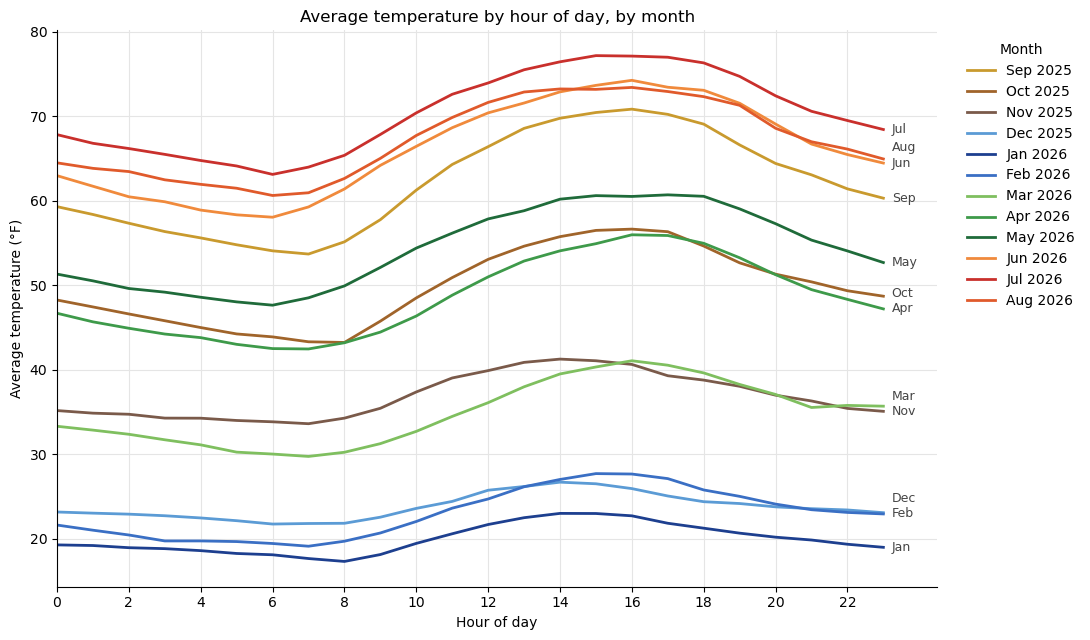

In [14]:
WEATHER_PLOT_PATH = 'onedrive-export/Data/eda/temperature_by_hour_by_month.png'

MONTH_COLORS = {
    12: '#5b9bd5', 1: '#1d3f8f', 2: '#3a6fc4',   # winter
    3: '#7fbf5f', 4: '#3e9a4a', 5: '#1f6b3a',    # spring
    6: '#f08a3c', 7: '#c9302c', 8: '#e05a2b',    # summer
    9: '#c99a2e', 10: '#a0642a', 11: '#7a5a4a',  # autumn
}

fig, ax = plt.subplots(figsize=(11, 6.5))
end_labels = []
for month in months:
    m = temp_by_hour.filter(pl.col('month') == month)
    ax.plot(m['hour'], m['avg_temp'], color=MONTH_COLORS[month.month],
            linewidth=2, label=month.strftime('%b %Y'))
    end_labels.append([m['avg_temp'][-1], month.strftime('%b'), m['hour'][-1]])

# Push end-of-line labels apart so they don't overlap.
MIN_GAP = 1.8  # degrees F between neighbouring labels
end_labels.sort()
for i in range(1, len(end_labels)):
    end_labels[i][0] = max(end_labels[i][0], end_labels[i - 1][0] + MIN_GAP)
for y, text, x in end_labels:
    ax.annotate(text, xy=(x, y), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color='#444444')

ax.set_title('Average temperature by hour of day, by month')
ax.set_xlabel('Hour of day')
ax.set_ylabel('Average temperature (°F)')
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 24.5)
ax.grid(True, color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(title='Month', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
fig.tight_layout()

fig.savefig(WEATHER_PLOT_PATH, dpi=150)
print(f'Saved temperature chart to {WEATHER_PLOT_PATH}')
plt.show()

## Save the weather data to DuckDB

To combine weather with electricity use, the weather data needs to sit next to the `ami` table and line up with it row for row. We write it to a second table, `weather`, in the same `avangrid.db` database.

**Matching the meter data's hour convention.** The weather file records the hour as clock time from 0 to 23, where 0 is the reading at midnight. The meter data uses `hour_ending` from 1 to 24, where 1 is the hour from midnight to 1 AM. We add 1 to each weather hour to get a matching `hour_ending` column, so the midnight reading lines up with the meter's first hour of the day.

**Matching column names and types.** The weather `date` column is renamed to `usage_date`, and `hour_ending` is stored as the same small-integer type as in `ami`. That way the tables join on identically named columns:

```sql
SELECT a.*, w.temp, w.humidity, w.windspeed
FROM ami a
JOIN weather w USING (usage_date, hour_ending)
```

We start from the cleaned `weather` dataframe built above, with the duplicate daylight-saving hour already removed, so each date and hour appears once and the join can't duplicate meter rows. The raw Excel `time` column and the 0–23 `hour` helper column are dropped because `hour_ending` replaces them.

The table is small, so unlike `ami` it is rebuilt on every run (`CREATE OR REPLACE`). It always reflects the current weather file.

In [15]:
weather_table = (
    weather.with_columns((pl.col('hour') + 1).cast(pl.Int8).alias('hour_ending'))
    .select(
        pl.col('date').alias('usage_date'),
        'hour_ending',
        'temp',
        'humidity',
        'windspeed',
    )
    .sort('usage_date', 'hour_ending')
)
assert weather_table['hour_ending'].min() == 1 and weather_table['hour_ending'].max() == 24

with duckdb.connect(DB_PATH) as con:
    con.execute('CREATE OR REPLACE TABLE weather AS SELECT * FROM weather_table')
    n_weather_rows = con.sql('SELECT COUNT(*) FROM weather').pl().item()

    # Check how many meter rows find a matching weather row.
    join_check = con.sql('''
        SELECT COUNT(*) AS ami_rows,
               COUNT(w.usage_date) AS ami_rows_with_weather
        FROM ami a
        LEFT JOIN weather w USING (usage_date, hour_ending)
    ''').pl()

print(f'Wrote {n_weather_rows:,} rows to table "weather" in {DB_PATH}')
join_check

Wrote 8,760 rows to table "weather" in onedrive-export/Data/avangrid.db


ami_rows,ami_rows_with_weather
i64,i64
298032553,298032553
